# Aula 2 - P1

## 2.1 Caracterização

In [1]:

import os
import glob
import re
import hashlib
import shutil
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from pathlib import Path
from PIL import Image

# Fix seeds
os.environ['PYTHONHASHSEED'] = '42'
tf.random.set_seed(42)
np.random.seed(42)
import random
random.seed(42)

DATA_DIR = r"c:\Users\vilar\Desktop\Mestrado\deeeplearning\data\raw\cell_images"

def compute_md5(file_path):
    hash_md5 = hashlib.md5()
    with open(file_path, "rb") as f:
        for chunk in iter(lambda: f.read(4096), b""):
            hash_md5.update(chunk)
    return hash_md5.hexdigest()

data = []
for ext in ('*.png', '*.jpg', '*.jpeg'):
    for path in Path(DATA_DIR).rglob(ext):
        label = path.parent.name
        # extract group using regex
        match = re.search(r'^(C\d+(?:P\d+)?)', path.name)
        group = match.group(1) if match else "Unknown"
        data.append({"path": str(path), "label": label, "grupo": group, "filename": path.name})

df = pd.DataFrame(data)

# Value counts
print("Value counts absolutos:")
print(df['label'].value_counts())
print("\nValue counts (%):")
print(df['label'].value_counts(normalize=True) * 100)


Value counts absolutos:
label
Parasitized    27558
Uninfected     27558
Name: count, dtype: int64

Value counts (%):
label
Parasitized    50.0
Uninfected     50.0
Name: proportion, dtype: float64


In [2]:

widths = []
heights = []
md5s = []
corrupted = []

for p in df['path']:
    try:
        with Image.open(p) as img:
            w, h = img.size
            widths.append(w)
            heights.append(h)
        md5s.append(compute_md5(p))
    except Exception as e:
        widths.append(np.nan)
        heights.append(np.nan)
        md5s.append(None)
        corrupted.append(p)

df['width'] = widths
df['height'] = heights
df['md5'] = md5s

print(f"Imagens corrompidas: {len(corrupted)}")
duplicates = df.duplicated(subset=['md5'], keep=False)
print(f"Duplicados (md5 igual): {duplicates.sum()}")

for label, group in df.groupby('label'):
    print(f"\nClasse {label}:")
    print(f"Mediana: {group['width'].median()} x {group['height'].median()}")
    print(f"Min: {group['width'].min()} x {group['height'].min()}")
    print(f"Max: {group['width'].max()} x {group['height'].max()}")


Imagens corrompidas: 0
Duplicados (md5 igual): 55116

Classe Parasitized:
Mediana: 133.0 x 133.0
Min: 46 x 40
Max: 394 x 385

Classe Uninfected:
Mediana: 130.0 x 130.0
Min: 49 x 49
Max: 247 x 235


## 2.2 Divisão sem fugas
Reaproveitando a divisão feita no D1, uma vez que já garantiu a estratificação 70/15/15 por classe e por grupo.

In [3]:

D1_SPLITS_DIR = r"c:\Users\vilar\Desktop\Mestrado\deeeplearning\splits"
df_train = pd.read_csv(os.path.join(D1_SPLITS_DIR, "train.csv"))
df_val = pd.read_csv(os.path.join(D1_SPLITS_DIR, "val.csv"))
df_test = pd.read_csv(os.path.join(D1_SPLITS_DIR, "test.csv"))

df_train['split'] = 'train'
df_val['split'] = 'val'
df_test['split'] = 'test'

df_splits = pd.concat([df_train, df_val, df_test], ignore_index=True)

df_splits['path'] = df_splits['relative_path'].apply(
    lambda x: os.path.join(r"c:\Users\vilar\Desktop\Mestrado\deeeplearning\data\raw", os.path.normpath(x))
)

# Merge para obter md5 e as outras informacoes (grupo tb ja vinha, mas validamos se eh o mesmo)
df_splits = df_splits.merge(df[['path', 'md5']], on='path', how='left')
df_splits.rename(columns={'class': 'label', 'id_grupo': 'grupo'}, inplace=True)
df_splits_out = df_splits[['path', 'label', 'grupo', 'md5', 'split']]
df_splits_out.to_csv("splits.csv", index=False)

# Checks
md5_train = set(df_splits_out[df_splits_out['split']=='train']['md5'].dropna())
md5_val = set(df_splits_out[df_splits_out['split']=='val']['md5'].dropna())
md5_test = set(df_splits_out[df_splits_out['split']=='test']['md5'].dropna())

print("Interseções de MD5:")
print("Train-Val:", len(md5_train.intersection(md5_val)))
print("Train-Test:", len(md5_train.intersection(md5_test)))
print("Val-Test:", len(md5_val.intersection(md5_test)))

grupo_train = set(df_splits_out[df_splits_out['split']=='train']['grupo'])
grupo_val = set(df_splits_out[df_splits_out['split']=='val']['grupo'])
grupo_test = set(df_splits_out[df_splits_out['split']=='test']['grupo'])

print("\nInterseções de Grupo:")
print("Train-Val:", len(grupo_train.intersection(grupo_val)))
print("Train-Test:", len(grupo_train.intersection(grupo_test)))
print("Val-Test:", len(grupo_val.intersection(grupo_test)))

print("\nDistribuição de classes por split:")
for split in ['train', 'val', 'test']:
    print(f"\nSplit {split}:")
    print(df_splits_out[df_splits_out['split']==split]['label'].value_counts(normalize=True) * 100)


Interseções de MD5:
Train-Val: 0
Train-Test: 0
Val-Test: 0

Interseções de Grupo:
Train-Val: 0
Train-Test: 0
Val-Test: 0

Distribuição de classes por split:

Split train:
label
Parasitized    50.123839
Uninfected     49.876161
Name: proportion, dtype: float64

Split val:
label
Parasitized    50.036523
Uninfected     49.963477
Name: proportion, dtype: float64

Split test:
label
Uninfected     50.626382
Parasitized    49.373618
Name: proportion, dtype: float64


## 2.3 Baseline
Criando as pastas e treinando a rede.

In [4]:

import platform

split_base_dir = "split"
os.makedirs(split_base_dir, exist_ok=True)
for split in ['train', 'val', 'test']:
    for label in df_splits_out['label'].unique():
        os.makedirs(os.path.join(split_base_dir, split, label), exist_ok=True)

# criar as imagens
for _, row in df_splits_out.iterrows():
    src = row['path']
    dst = os.path.join(split_base_dir, row['split'], row['label'], os.path.basename(src))
    if not os.path.exists(dst):
        try:
            os.symlink(src, dst)
        except OSError:
            shutil.copy2(src, dst)

img_size = (180, 180)
batch_size = 32

train_ds = keras.utils.image_dataset_from_directory(
    os.path.join(split_base_dir, 'train'),
    image_size=img_size,
    batch_size=batch_size,
    label_mode='int',
    shuffle=True,
    seed=42
)

val_ds = keras.utils.image_dataset_from_directory(
    os.path.join(split_base_dir, 'val'),
    image_size=img_size,
    batch_size=batch_size,
    label_mode='int',
    shuffle=False
)


Found 19380 files belonging to 2 classes.


Found 4107 files belonging to 2 classes.


In [5]:

inputs = keras.Input(shape=(180, 180, 3))
x = layers.Rescaling(1./255)(inputs)
for filters in [32, 64, 128, 256]:
    x = layers.Conv2D(filters, 3, activation='relu')(x)
    x = layers.MaxPooling2D(2)(x)
x = layers.GlobalAveragePooling2D()(x)
outputs = layers.Dense(2, activation='softmax')(x)

model = keras.Model(inputs, outputs)
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

model.summary()


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 178, 178, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 89, 89, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 87, 87, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 43, 43, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 41, 41, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 20, 20, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 18, 18, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 9, 9, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 2)              │           514 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 388,930 (1.48 MB)

 Trainable params: 388,930 (1.48 MB)

 Non-trainable params: 0 (0.00 B)

In [6]:

print("Cálculo manual dos parâmetros:")
print("Conv 1 (32 filtros): (3 * 3 * 3 + 1) * 32 =", (3*3*3 + 1)*32)
print("Conv 2 (64 filtros): (3 * 3 * 32 + 1) * 64 =", (3*3*32 + 1)*64)


Cálculo manual dos parâmetros:
Conv 1 (32 filtros): (3 * 3 * 3 + 1) * 32 = 896
Conv 2 (64 filtros): (3 * 3 * 32 + 1) * 64 = 18496


In [7]:

import time

start_time = time.time()
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=30
)
end_time = time.time()
print(f"Tempo de treino: {end_time - start_time:.2f} segundos")

val_labels = []
for images, labels in val_ds:
    val_labels.extend(labels.numpy())
majority_class_count = max(np.bincount(val_labels))
majority_acc = majority_class_count / len(val_labels)
print(f"Acurácia do classificador maioritário no val: {majority_acc:.4f}")
print(f"Acurácia final no val (última época): {history.history['val_accuracy'][-1]:.4f}")


Epoch 1/30


C:\Users\vilar\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


  1/606 ━━━━━━━━━━━━━━━━━━━━ 11:36 1s/step - accuracy: 0.5938 - loss: 0.6889

  2/606 ━━━━━━━━━━━━━━━━━━━━ 1:24 140ms/step - accuracy: 0.5625 - loss: 0.6972

  3/606 ━━━━━━━━━━━━━━━━━━━━ 1:24 140ms/step - accuracy: 0.5417 - loss: 0.6973

...

605/606 ━━━━━━━━━━━━━━━━━━━━ 0s 200ms/step - accuracy: 0.9835 - loss: 0.0459

606/606 ━━━━━━━━━━━━━━━━━━━━ 0s 200ms/step - accuracy: 0.9835 - loss: 0.0460

606/606 ━━━━━━━━━━━━━━━━━━━━ 129s 213ms/step - accuracy: 0.9835 - loss: 0.0460 - val_accuracy: 0.9530 - val_loss: 0.2340


Tempo de treino: 3244.91 segundos


Acurácia do classificador maioritário no val: 0.5004
Acurácia final no val (última época): 0.9530


## 2.4 Curvas e diagnóstico

Melhor época (menor val_loss): 10
Acc treino na melhor época: 0.9537
Acc val na melhor época: 0.9637


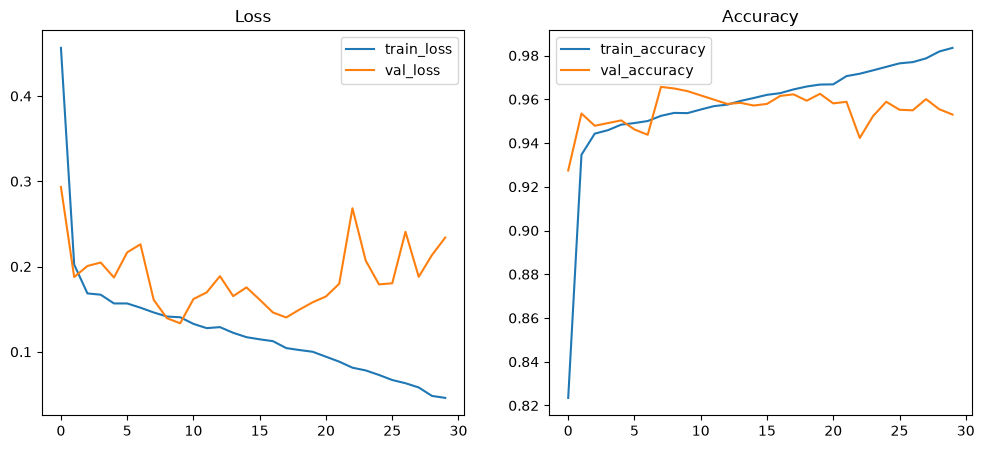

In [8]:

history_df = pd.DataFrame(history.history)
history_df.to_csv('history_baseline.csv', index=False)

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(history_df['loss'], label='train_loss')
plt.plot(history_df['val_loss'], label='val_loss')
plt.title('Loss')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history_df['accuracy'], label='train_accuracy')
plt.plot(history_df['val_accuracy'], label='val_accuracy')
plt.title('Accuracy')
plt.legend()
plt.savefig('curvas_baseline.png')

best_epoch = history_df['val_loss'].idxmin()
print(f"Melhor época (menor val_loss): {best_epoch + 1}")
print(f"Acc treino na melhor época: {history_df.loc[best_epoch, 'accuracy']:.4f}")
print(f"Acc val na melhor época: {history_df.loc[best_epoch, 'val_accuracy']:.4f}")


## 2.5 Data Augmentation
Modelo com RandomFlip, RandomRotation e RandomContrast.

In [9]:
from tensorflow.keras.layers import RandomFlip, RandomRotation, RandomContrast

inputs_aug = keras.Input(shape=(180, 180, 3))
x = RandomFlip("horizontal_and_vertical", seed=42)(inputs_aug)
x = RandomRotation(0.25, seed=42)(x)
x = RandomContrast(0.2, seed=42)(x)
x = layers.Rescaling(1./255)(x)

for filters in [32, 64, 128, 256]:
    x = layers.Conv2D(filters, 3, activation="relu")(x)
    x = layers.MaxPooling2D(2)(x)
x = layers.GlobalAveragePooling2D()(x)
outputs_aug = layers.Dense(2, activation="softmax")(x)

model_aug = keras.Model(inputs_aug, outputs_aug)
model_aug.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])

model_aug.summary()


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip (RandomFlip)        │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 180, 180, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_contrast                 │ (None, 180, 180, 3)    │             0 │
│ (RandomContrast)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_1 (Rescaling)         │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 178, 178, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 89, 89, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 87, 87, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 43, 43, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 41, 41, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 20, 20, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 18, 18, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 9, 9, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 2)              │           514 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 388,930 (1.48 MB)

 Trainable params: 388,930 (1.48 MB)

 Non-trainable params: 0 (0.00 B)

In [10]:
import time
start_time = time.time()
history_aug = model_aug.fit(
    train_ds,
    validation_data=val_ds,
    epochs=30
)
end_time = time.time()
print(f"Tempo de treino (Augmentation): {end_time - start_time:.2f} segundos")


Epoch 1/30


C:\Users\vilar\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


  1/606 ━━━━━━━━━━━━━━━━━━━━ 20:21 2s/step - accuracy: 0.5312 - loss: 0.6913

  2/606 ━━━━━━━━━━━━━━━━━━━━ 1:57 194ms/step - accuracy: 0.5469 - loss: 0.6858

  3/606 ━━━━━━━━━━━━━━━━━━━━ 1:57 194ms/step - accuracy: 0.5312 - loss: 0.6846

...

604/606 ━━━━━━━━━━━━━━━━━━━━ 0s 159ms/step - accuracy: 0.9589 - loss: 0.1242

605/606 ━━━━━━━━━━━━━━━━━━━━ 0s 159ms/step - accuracy: 0.9589 - loss: 0.1243

606/606 ━━━━━━━━━━━━━━━━━━━━ 0s 159ms/step - accuracy: 0.9589 - loss: 0.1243

606/606 ━━━━━━━━━━━━━━━━━━━━ 102s 169ms/step - accuracy: 0.9589 - loss: 0.1243 - val_accuracy: 0.9615 - val_loss: 0.1323


Tempo de treino (Augmentation): 3397.58 segundos


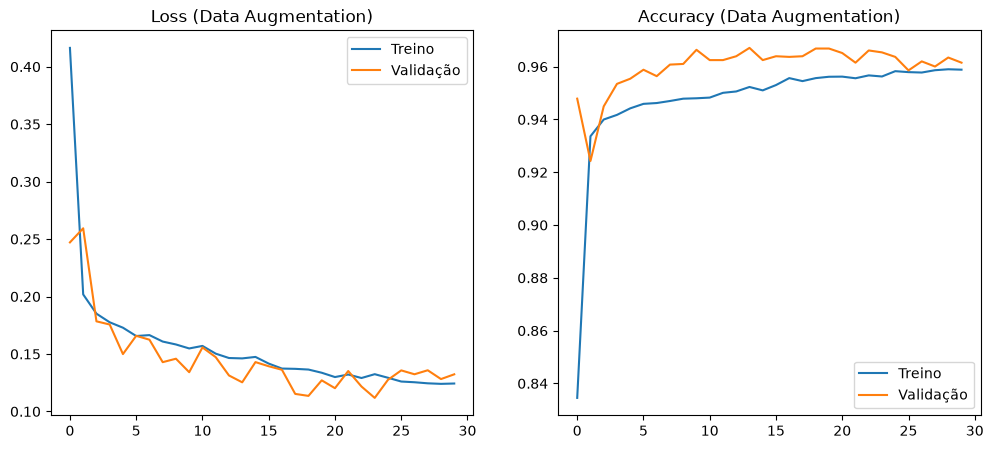

In [11]:
import pandas as pd
import matplotlib.pyplot as plt

history_aug_df = pd.DataFrame(history_aug.history)
history_aug_df.to_csv("history_aug.csv", index=False)

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(history_aug.history["loss"], label="Treino")
plt.plot(history_aug.history["val_loss"], label="Validação")
plt.title("Loss (Data Augmentation)")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history_aug.history["accuracy"], label="Treino")
plt.plot(history_aug.history["val_accuracy"], label="Validação")
plt.title("Accuracy (Data Augmentation)")
plt.legend()

plt.savefig("curvas_aug.png")
plt.show()
